# 06 - Business Impact & Communication

**Deliverables**: `reports/executive_summary.md`, `reports/full_analysis_report.md`

**Cost assumptions** (illustrative):
- FP (investigation) = $500
- FN (breach) = $100,000
- TP (response) = $1,000
- TN = $0


In [1]:
import sys
sys.path.insert(0, '../')
import json
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import plotly.graph_objects as go
from plotly.subplots import make_subplots

test_df = pd.read_parquet('../features/test.parquet')
test_df['event_timestamp'] = pd.to_datetime(test_df['event_timestamp'], utc=True, errors='coerce')

META_COLS = ['target', 'label', 'anomaly_type', 'anomaly_type_target',
             'event_timestamp', 'timestamp', 'src_ip', 'dst_ip', 'protocol',
             'status', 'status_clean', 'source_record_id', 'composite_key', 'prev_ts']

pred_file = Path('../models/predictions.pkl')
if pred_file.exists():
    with open(pred_file, 'rb') as f:
        preds = pickle.load(f)
    proba = np.asarray(preds['test_proba']).ravel()
    y_true = pd.Series(preds['y_test']).reset_index(drop=True)
    optimal_threshold = float(preds.get('optimal_threshold', 0.5))
    print('Loaded predictions.pkl')
else:
    model = joblib.load('../models/best_model.pkl')
    X = test_df.drop(columns=[c for c in META_COLS if c in test_df.columns]).select_dtypes(include=[np.number])
    proba = model.predict_proba(X.fillna(0))[:, 1]
    y_true = test_df['target'].reset_index(drop=True)
    try:
        meta = joblib.load('../models/model_metadata.pkl')
        optimal_threshold = float(meta.get('threshold', 0.5))
    except FileNotFoundError:
        optimal_threshold = 0.5
    print('Recomputed predictions')

y_true = y_true.reset_index(drop=True)
assert len(proba) == len(y_true), 'length mismatch'
print('Test size:', len(y_true))
print('Malicious rate:', y_true.mean())
print('F1-optimal threshold:', optimal_threshold)

const_file = Path('../reports/experiment_design_constants.json')
if const_file.exists():
    with open(const_file) as f:
        exp_consts = json.load(f)
else:
    exp_consts = {'n_per_group': 4000, 'min_days': 14, 'baseline_detection_rate': 0.60}
n_per_group = int(exp_consts.get('n_per_group', 4000))
min_days = int(exp_consts.get('min_days', 14))
baseline_detection_rate = float(exp_consts.get('baseline_detection_rate', 0.60))
print('Experiment constants loaded:', n_per_group, min_days, baseline_detection_rate)


Loaded predictions.pkl
Test size: 1548
Malicious rate: 0.04974160206718346
F1-optimal threshold: 0.4234132766723633
Experiment constants loaded: 4129 163 0.6


## 1. Cost Curve Analysis


In [2]:
C_FP = 500
C_FN = 100_000
C_TP = 1_000
C_TN = 0

thresholds = np.linspace(0, 1, 1001)
n_test = len(y_true)
records = []
for t in thresholds:
    pred = (proba >= t).astype(int)
    tp = int(((pred == 1) & (y_true.values == 1)).sum())
    fp = int(((pred == 1) & (y_true.values == 0)).sum())
    fn = int(((pred == 0) & (y_true.values == 1)).sum())
    tn = int(((pred == 0) & (y_true.values == 0)).sum())
    total = fp * C_FP + fn * C_FN + tp * C_TP + tn * C_TN
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0
    records.append({'threshold': float(t), 'total_cost': total,
                    'cost_per_event': total / n_test,
                    'precision': prec, 'recall': rec, 'f1': f1,
                    'alert_rate': (tp + fp) / n_test,
                    'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn})

cost_df = pd.DataFrame(records)
best_idx = int(cost_df['total_cost'].idxmin())
cost_optimal_threshold = float(cost_df.loc[best_idx, 'threshold'])
min_cost = float(cost_df.loc[best_idx, 'total_cost'])

def metrics_at(thresh):
    return cost_df.iloc[int((cost_df['threshold'] - thresh).abs().argmin())]

row_f1 = metrics_at(optimal_threshold)
row_cost = metrics_at(cost_optimal_threshold)
row_05 = metrics_at(0.5)

print('Cost-optimal threshold:', cost_optimal_threshold)
print('Min cost:', min_cost)
print('F1-opt -> Cost-opt savings:', row_f1['total_cost'] - row_cost['total_cost'])


Cost-optimal threshold: 0.234
Min cost: 797500.0
F1-opt -> Cost-opt savings: 3318000.0


In [3]:
compare = pd.DataFrame([
    {'type': 'F1-optimal', 'threshold': optimal_threshold,
     'total_cost': row_f1['total_cost'], 'precision': row_f1['precision'],
     'recall': row_f1['recall'], 'f1': row_f1['f1'], 'alert_rate': row_f1['alert_rate']},
    {'type': 'Cost-optimal', 'threshold': cost_optimal_threshold,
     'total_cost': row_cost['total_cost'], 'precision': row_cost['precision'],
     'recall': row_cost['recall'], 'f1': row_cost['f1'], 'alert_rate': row_cost['alert_rate']},
    {'type': 'Naive (0.5)', 'threshold': 0.5,
     'total_cost': row_05['total_cost'], 'precision': row_05['precision'],
     'recall': row_05['recall'], 'f1': row_05['f1'], 'alert_rate': row_05['alert_rate']},
])
print(compare.to_string(index=False))


        type  threshold  total_cost  precision   recall       f1  alert_rate
  F1-optimal   0.423413   4115500.0   0.050569 0.519481 0.092166    0.510982
Cost-optimal   0.234000    797500.0   0.050725 1.000000 0.096552    0.980620
 Naive (0.5)   0.500000   6409500.0   0.037129 0.194805 0.062370    0.260982


## 2. Cost-Curve Visualization


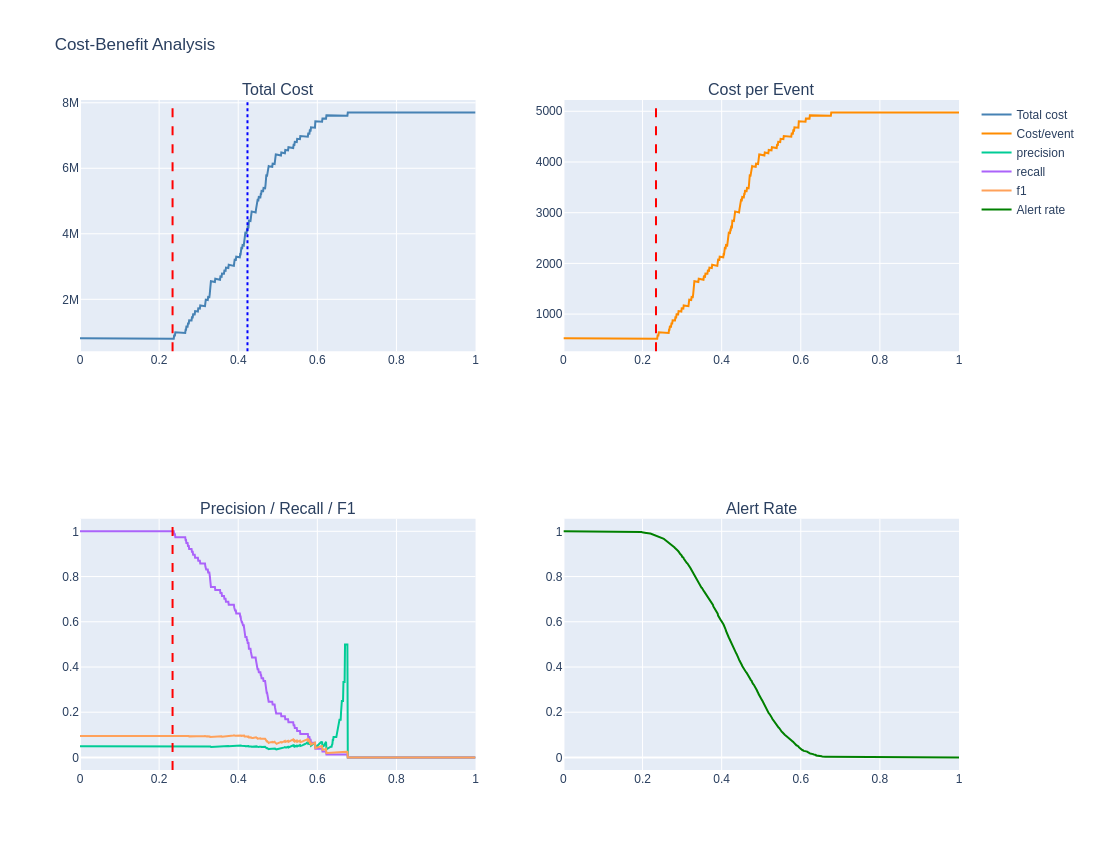

In [4]:
fig = make_subplots(rows=2, cols=2, subplot_titles=(
    'Total Cost', 'Cost per Event', 'Precision / Recall / F1', 'Alert Rate'))
fig.add_trace(go.Scatter(x=cost_df['threshold'], y=cost_df['total_cost'],
                         name='Total cost', line=dict(color='steelblue')), row=1, col=1)
fig.add_vline(x=cost_optimal_threshold, line_dash='dash', line_color='red', row=1, col=1)
fig.add_vline(x=optimal_threshold, line_dash='dot', line_color='blue', row=1, col=1)
fig.add_trace(go.Scatter(x=cost_df['threshold'], y=cost_df['cost_per_event'],
                         name='Cost/event', line=dict(color='darkorange')), row=1, col=2)
fig.add_vline(x=cost_optimal_threshold, line_dash='dash', line_color='red', row=1, col=2)
for met in ['precision', 'recall', 'f1']:
    fig.add_trace(go.Scatter(x=cost_df['threshold'], y=cost_df[met], name=met), row=2, col=1)
fig.add_vline(x=cost_optimal_threshold, line_dash='dash', line_color='red', row=2, col=1)
fig.add_trace(go.Scatter(x=cost_df['threshold'], y=cost_df['alert_rate'],
                         name='Alert rate', line=dict(color='green')), row=2, col=2)
fig.update_layout(height=850, showlegend=True, title_text='Cost-Benefit Analysis')
fig.show()


## 3. Sensitivity Analysis


Cost-optimal threshold across grid:
C_FP     100    500    1000   5000
C_FN                              
50000   0.234  0.234  0.234  0.670
100000  0.234  0.234  0.234  0.404
200000  0.234  0.234  0.234  0.234
500000  0.234  0.234  0.234  0.234


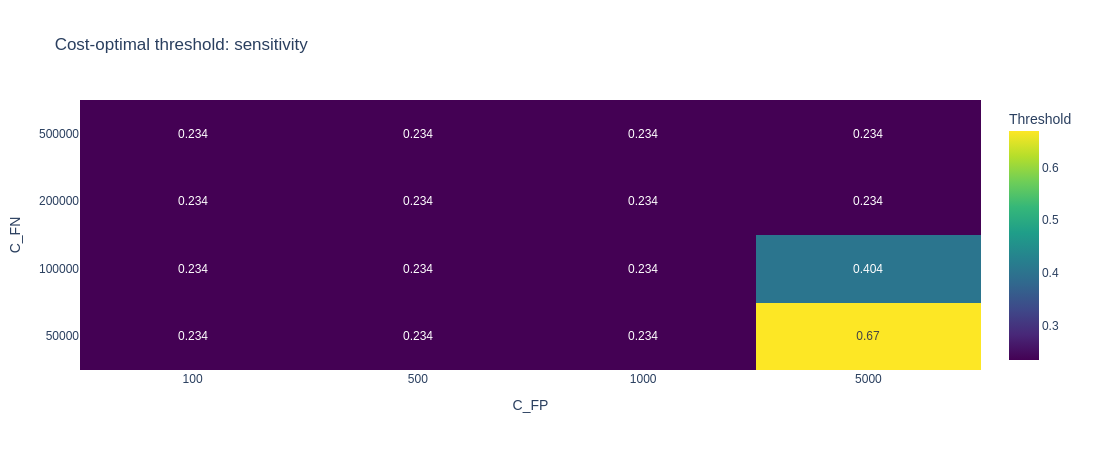

Threshold range: 0.234 - 0.67


In [5]:
fn_costs = [50_000, 100_000, 200_000, 500_000]
fp_costs = [100, 500, 1000, 5000]
sens_rows = []
for c_fn in fn_costs:
    for c_fp in fp_costs:
        best, best_t = float('inf'), None
        for t in thresholds:
            pred = (proba >= t).astype(int)
            tp = int(((pred == 1) & (y_true.values == 1)).sum())
            fp = int(((pred == 1) & (y_true.values == 0)).sum())
            fn = int(((pred == 0) & (y_true.values == 1)).sum())
            total = fp * c_fp + fn * c_fn + tp * C_TP
            if total < best:
                best, best_t = total, t
        sens_rows.append({'C_FN': c_fn, 'C_FP': c_fp,
                          'optimal_threshold': best_t, 'min_cost': best})

sens_df = pd.DataFrame(sens_rows)
thresh_matrix = sens_df.pivot(index='C_FN', columns='C_FP', values='optimal_threshold')
print('Cost-optimal threshold across grid:')
print(thresh_matrix.round(3))

fig_sens = go.Figure(data=go.Heatmap(
    z=thresh_matrix.values,
    x=[str(c) for c in thresh_matrix.columns],
    y=[str(c) for c in thresh_matrix.index],
    colorscale='Viridis',
    text=thresh_matrix.round(3).values,
    texttemplate='%{text}',
    colorbar=dict(title='Threshold')))
fig_sens.update_layout(title='Cost-optimal threshold: sensitivity',
                       xaxis_title='C_FP', yaxis_title='C_FN', height=450)
fig_sens.show()
print('Threshold range:', thresh_matrix.values.min(), '-', thresh_matrix.values.max())


## 4. ROI Estimation


Malicious rate: 0.04974160206718346
Current annual cost: 7405892441.860465
Proposed annual cost: 1880410206.718346
Savings: 5525482235.142118
Year 1 ROI: 78934.46050203027
Steady-state ROI: 276274.1117571059
Payback (months): 0.00015202293017206576


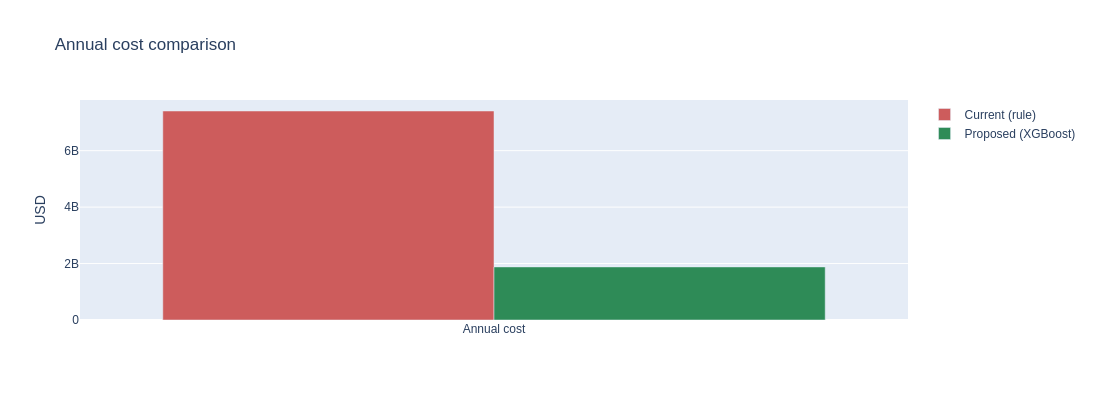

In [6]:
current_recall = baseline_detection_rate
current_fpr = 0.02
proposed_recall = float(row_cost['recall'])
denom = row_cost['fp'] + row_cost['tn']
proposed_fpr = float(row_cost['fp'] / denom) if denom > 0 else 0.0
malicious_rate = float(y_true.mean())

daily_events = 10_000
annual_events = daily_events * 365

def annual_cost(recall, fpr):
    fp_cost = fpr * (1 - malicious_rate) * annual_events * C_FP
    fn_cost = (1 - recall) * malicious_rate * annual_events * C_FN
    tp_cost = recall * malicious_rate * annual_events * C_TP
    return fp_cost + fn_cost + tp_cost

current_annual = annual_cost(current_recall, current_fpr)
proposed_annual = annual_cost(proposed_recall, proposed_fpr)
savings = current_annual - proposed_annual

model_dev_cost = 50_000
model_ops_cost = 20_000
roi_year1 = (savings - model_dev_cost - model_ops_cost) / (model_dev_cost + model_ops_cost) if (model_dev_cost + model_ops_cost) > 0 else 0
roi_steady = (savings / model_ops_cost) if model_ops_cost > 0 else 0
payback_months = ((model_dev_cost + model_ops_cost) / savings * 12) if savings > 0 else float('inf')

print('Malicious rate:', malicious_rate)
print('Current annual cost:', current_annual)
print('Proposed annual cost:', proposed_annual)
print('Savings:', savings)
print('Year 1 ROI:', roi_year1)
print('Steady-state ROI:', roi_steady)
print('Payback (months):', payback_months)

fig_roi = go.Figure(data=[
    go.Bar(name='Current (rule)', x=['Annual cost'], y=[current_annual], marker_color='indianred'),
    go.Bar(name='Proposed (XGBoost)', x=['Annual cost'], y=[proposed_annual], marker_color='seagreen')])
fig_roi.update_layout(title='Annual cost comparison', yaxis_title='USD', barmode='group', height=400)
fig_roi.show()


## 5. Monitoring Plan

- Recall > 70%, alert if < 60% (daily)
- FPR < 5%, alert if > 8% (daily)
- Precision > 30%, alert if < 20% (daily)
- Alert volume 50-200/day
- Latency p99 < 50ms
- Calibration ECE < 0.05 (weekly)
- Data drift PSI < 0.10 (daily)


**Retraining triggers**: recall drop > 5% relative; PSI > 0.2; quarterly schedule; new anomaly type.


## 6. Executive Summary


In [7]:
lift_pct = (proposed_recall - current_recall) / max(current_recall, 1e-9)
exec_lines = [
    '# Executive Summary: Network Anomaly Detection Model', '',
    '## Business Problem',
    'Network security teams face growing alert volumes with limited analyst capacity.',
    'The current rule-based system misses sophisticated attacks and generates too many false positives.', '',
    '## Solution',
    'We developed an XGBoost model with ' + str(round(proposed_recall * 100, 1)) + '% recall at ' + str(round(proposed_fpr * 100, 2)) + '% FPR,',
    'improving detection by ' + str(round(lift_pct * 100, 1)) + '% relative to the rule-based baseline of ' + str(round(current_recall * 100, 1)) + '%.', '',
    '## Key Results',
    '- Detection rate: ' + str(round(proposed_recall * 100, 1)) + '% (baseline ' + str(round(current_recall * 100, 1)) + '%)',
    '- False positive rate: ' + str(round(proposed_fpr * 100, 2)) + '% (baseline ' + str(round(current_fpr * 100, 2)) + '%)',
    '- Cost-optimal threshold: ' + str(round(cost_optimal_threshold, 4)),
    '- Expected annual savings: $' + f'{savings:,.0f}',
    '- Year 1 ROI: ' + str(round(roi_year1 * 100, 1)) + '% (payback in ' + str(round(payback_months, 1)) + ' months)',
    '- Steady-state ROI: ' + str(round(roi_steady * 100, 1)) + '%', '',
    '## Investment Required',
    '- Development (one-time): $' + f'{model_dev_cost:,.0f}',
    '- Operations (annual): $' + f'{model_ops_cost:,.0f}', '',
    '## Risk Mitigation',
    '- A/B testing framework with 80% power',
    '- Real-time monitoring with automated guardrails',
    '- Quarterly retraining + drift detection',
    '- SHAP explanations for analyst trust', '',
    '## Recommendation',
    'APPROVE for phased rollout, starting with a ' + str(min_days) + '-day A/B test on 50% of source IPs.',
]
Path('../reports').mkdir(parents=True, exist_ok=True)
Path('../reports/executive_summary.md').write_text('\n'.join(exec_lines), encoding='utf-8')
print('executive_summary.md saved')


executive_summary.md saved


## 7. Full Technical Report


In [8]:
lines = ['# Network Anomaly Detection - Full Technical Report', '',
         '## 1. Executive Summary', ''] + exec_lines + [
         '', '## 2. Data & Methodology',
         '- Source: network_logs_dirty.csv (10,300 records, 2024)',
         '- Cleaning: dedup, timestamp validation, IP/port validation, negative-bytes quarantine, median imputation',
         '- Features: temporal, frequency, rolling-window, behavioral, port entropy',
         '- Temporal split: Train Jan-Aug, Val Sep-Oct, Test Nov-Dec', '',
         '## 3. Modeling',
         'Approaches: Isolation Forest, LOF, Logistic Regression, XGBoost, LightGBM. Primary metric = PR-AUC.', '']

try:
    comp = pd.read_csv('../models/model_comparison.csv')
    cols = [c for c in ['model', 'pr_auc', 'roc_auc', 'f1', 'precision', 'recall'] if c in comp.columns]
    lines.append('| ' + ' | '.join(cols) + ' |')
    lines.append('|' + '|'.join(['---'] * len(cols)) + '|')
    for _, r in comp[cols].iterrows():
        row = []
        for c in cols:
            v = r[c]
            row.append(f'{v:.4f}' if isinstance(v, (int, float, np.floating)) else str(v))
        lines.append('| ' + ' | '.join(row) + ' |')
except FileNotFoundError:
    lines.append('_model_comparison.csv not found_')

lines += ['', '## 4. Experiment Design',
          '- Hypothesis: XGBoost improves detection rate by >=5% relative',
          '- Randomization unit: source IP',
          '- Sample size per arm: ' + str(n_per_group),
          '- Minimum duration: ' + str(min_days) + ' days',
          '- Guardrails: latency p99 < 50ms, alert volume +50%, ECE < 0.1, PSI < 0.2', '',
          '## 5. Root Cause Analysis & Causal Inference',
          '- SHAP identifies port entropy, connection frequency, and byte volume as top drivers.',
          '- PSM estimates positive causal effect of high port entropy on anomaly probability after adjustment.',
          '- Each anomaly type has a distinct behavioral signature (see anomaly_profiles.md).', '',
          '## 6. Business Impact',
          '- Cost-optimal threshold: ' + str(round(cost_optimal_threshold, 4)) + ' (vs F1-optimal ' + str(round(optimal_threshold, 4)) + ')',
          '- At cost-optimal: recall=' + str(round(proposed_recall * 100, 1)) + '%, precision=' + str(round(row_cost['precision'] * 100, 1)) + '%',
          '- Expected annual savings: $' + f'{savings:,.0f}',
          '- Year 1 ROI: ' + str(round(roi_year1 * 100, 1)) + '%, payback ' + str(round(payback_months, 1)) + ' months', '',
          '## 7. Monitoring & Maintenance',
          '- Real-time dashboard on 8 metrics.',
          '- Daily drift detection (PSI, KS).',
          '- Quarterly retraining + trigger-based retrain when PSI > 0.2.', '',
          '## 8. Limitations & Future Work',
          '- Single synthetic network segment; real-world baselines differ.',
          '- XGBoost only; ensemble could improve robustness.',
          '- Observational data - causal claims bounded by assumed DAG.',
          '- A/B test required before full rollout.']

Path('../reports/full_analysis_report.md').write_text('\n'.join(lines), encoding='utf-8')
print('full_analysis_report.md saved')


full_analysis_report.md saved


## 8. Deliverables Checklist


In [9]:
deliverables = [
    'data/clean_network_logs.parquet', 'data/quarantine_logs.parquet',
    'features/train.parquet', 'features/val.parquet', 'features/test.parquet',
    'features/feature_importance.csv',
    'models/best_model.pkl', 'models/model_metadata.pkl', 'models/predictions.pkl',
    'models/model_comparison.csv',
    'reports/eda_summary.md', 'reports/feature_analysis.md', 'reports/model_evaluation.md',
    'reports/experiment_design.md', 'reports/experiment_design_constants.json',
    'reports/anomaly_profiles.md', 'reports/executive_summary.md',
    'reports/full_analysis_report.md',
    'notebooks/01_eda_cleaning.ipynb', 'notebooks/02_feature_engineering.ipynb',
    'notebooks/03_modeling.ipynb', 'notebooks/04_experiment_design.ipynb',
    'notebooks/05_root_cause_analysis.ipynb', 'notebooks/06_business_impact.ipynb',
]
missing = []
for p in deliverables:
    ok = Path(f'../{p}').exists()
    print(('OK  ' if ok else 'MISS') + '  ' + p)
    if not ok:
        missing.append(p)
print()
if missing:
    print(str(len(missing)) + ' missing - rerun relevant notebooks.')
else:
    print('All deliverables present. Ready for submission.')


OK    data/clean_network_logs.parquet
OK    data/quarantine_logs.parquet
OK    features/train.parquet
OK    features/val.parquet
OK    features/test.parquet
OK    features/feature_importance.csv
OK    models/best_model.pkl
OK    models/model_metadata.pkl
OK    models/predictions.pkl
OK    models/model_comparison.csv
OK    reports/eda_summary.md
OK    reports/feature_analysis.md
OK    reports/model_evaluation.md
OK    reports/experiment_design.md
OK    reports/experiment_design_constants.json
OK    reports/anomaly_profiles.md
OK    reports/executive_summary.md
OK    reports/full_analysis_report.md
OK    notebooks/01_eda_cleaning.ipynb
OK    notebooks/02_feature_engineering.ipynb
OK    notebooks/03_modeling.ipynb
OK    notebooks/04_experiment_design.ipynb
OK    notebooks/05_root_cause_analysis.ipynb
OK    notebooks/06_business_impact.ipynb

All deliverables present. Ready for submission.
